# **Coin Detection, Classification, and Counting**

## Image Processing and Computer Vision - Assignment Module #1


Alessandro Teodori (0001247539) alessandro.teodori3@studio.unibo.it

Juan Guillermo Jaramillo Saa (0001217725) juan.jaramillosaa@studio.unibo.it

Ubalducci Michele (0001226810) michele.ubalducci@studio.unibo.it


## Task & Architecture Overview

The objective of this assignment is to design and implement an end-to-end computer vision pipeline based strictly on traditional image processing techniques to:
1. **Detect** all Euro coins in heterogeneous scenes with complex backgrounds, perspective variations, and variable illumination.
2. **Classify** each detected coin into one of the 8 official Euro denominations.
3. **Compute Monetary Value** by outputting the partial sum for each image and the total grand amount across the target dataset.

---

### Engineering Choices
During our preliminary experiments, our first intuition was to rely on standard local feature matchers such as **SIFT**. However, we quickly observed that SIFT struggles severely on this specific task:
Euro coins have subtle 3D metallic features. Under varying illumination angles, directional shadows cast by the engravings constantly shift and deform the local gradient orientations, causing keypoint descriptors of the same coin to look drastically different across images. Furthermore, surface reflections and wear produce fragile, non-repeatable keypoints.

So we resorted to a more practical approach: after detecting the coins in the images we compared their color and relative size to find possible matches. To still leverage the coin engravings without relying on local descriptors, we decided to extract the edges, unwarp them into polar
  coordinates ($50 \times 360$), and match them against reference templates using circular Zero-Normalized Cross-Correlation. This gave us a kind of "fingerprint" for each coin that we could rely on without using SIFT.


### Two-Phase Pipeline Strategy

Our proposed solution is structured into two complementary phases. The first extracts all the necessary information from the given reference images in the reference set, while the second uses those information to perform the classification of the coins in the target set.

```
       [ Reference Set ]                            [ Target Set  ]
             |                                             |
             |                                    Preprocessing for coin detection
             |                                             |
    Color Calibration:                           Coin detection via template matching (Hough Circles)
    - CIELAB Delta b* extraction                           |
    - White-Patch HSV Hue extraction             Color Classification of Coins
             |                                             |
    Rotational Polar Templates                    Polar Unwarp of Coins
             \                                            /
              \                                          /
               ---> [ Classification Decision Tree ] <---
                                    |
                     +--------------+--------------+
                     |                             |
             N == 1 Coin                    N > 1 Coins
                     |                             |
            Circular ZNCC Matching         Soft-CSP on color, scale and ZNCC Matching

                     |                             |
                     +--------------+--------------+
                                    |
                      [ Monetary Sum & Evaluation ]
```

What follows is a brief description of the steps in the pipeline, each of which will be explored further in the following sections of the notebook:

1. **Offline Phase (Reference Calibration)**:
   - Normalizes ROIs (Region of Interest) of the 8 canonical reference coins to a standardized canvas ($250 \times 250$ px, $R=100$ px).
   - Calibrates the physical color boundaries: $\Delta b^*$ separating bimetallic coins ($1$€ and $2$€) from single-metal coins, and median Hue in HSV under white-patch color constancy separating copper ($1$c, $2$c, $5$c) from gold ($10$c, $20$c, $50$c).
   - Generates rotation-invariant $50 \times 360$ polar templates via Canny edge detection and linear polar unwarping.

2. **Online Phase (Target Classification)**:
   - **Detection**: Image preprocessing followed by Hough Circles transform, validated by radial gradient coherence ($\ge 0.85$ edge support score).
   - **Color Categorization**: Evaluates $\Delta b^*$ and White-Patch Hue with continuous confidence distance.
   - **Classification Branch**:
     * **Single-Coin Images**: When an image contains only one coin, no relative scale is available. We prune candidate denominations by color group and match against the reference polar templates using circular Zero-Normalized Cross-Correlation (ZNCC) computed efficiently via FFT across all 360 angular orientations.
     * **Multi-Coin Images**: When multiple coins share the same focal plane, they must obey physical scale consistency. We formulate an optimal assignment via a **Soft Constraint Satisfaction Problem (Soft-CSP)** that jointly minimizes scale coefficient of variation, pairwise diameter ratio errors, and monotonicity violations, while incorporating soft color penalties and dynamic ZNCC matching for tie-breaking and scale disambiguation.

In [18]:
# ==============================================================================
# ENVIRONMENT SETUP: GOOGLE COLAB VS LOCAL EXECUTION
# ==============================================================================
# Set IS_COLAB to True when running in Google Colab; False for local execution.
IS_COLAB = False

import os
import sys
import zipfile
from pathlib import Path

if IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    
    # Copy dataset archive from Google Drive and extract
    os.system("cp -r /content/drive/MyDrive/AssignmentsIPCV/coin_dataset.zip ./")
    os.system("unzip -q -o coin_dataset.zip")
    DATASET_DIR = Path("coin_dataset")
else:
    DATASET_DIR = Path("coin_dataset")
    if not DATASET_DIR.exists() and Path("coin_dataset.zip").exists():
        print("Extracting local coin_dataset.zip...")
        with zipfile.ZipFile("coin_dataset.zip", "r") as zip_ref:
            zip_ref.extractall(".")

REF_DIR = DATASET_DIR / "reference_set"
TARGET_DIR = DATASET_DIR / "target_set"

print(f"Reference folder: {REF_DIR.resolve()} (exists: {REF_DIR.exists()})")
print(f"Target folder:    {TARGET_DIR.resolve()} (exists: {TARGET_DIR.exists()})")

Reference folder: C:\Users\Michele\Desktop\UNI\Primo Anno\CV\assignment\m1\project\2cents-X-IPCV\coin_dataset\reference_set (exists: True)
Target folder:    C:\Users\Michele\Desktop\UNI\Primo Anno\CV\assignment\m1\project\2cents-X-IPCV\coin_dataset\target_set (exists: True)


Below, we import the required libraries and define the official physical specifications of Euro coin, publicly available online.

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import json
import re
import itertools
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional, Any
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

# Official Euro coin diameters in millimeters
DIAMETERS_MM = {
    "1cent": 16.25,
    "2cent": 18.75,
    "10cent": 19.75,
    "5cent": 21.25,
    "20cent": 22.25,
    "1euro": 23.25,
    "50cent": 24.25,
    "2euro": 25.75
}

# Monetary value in Euros for each denomination
COIN_VALUES = {
    "1cent": 0.01,
    "2cent": 0.02,
    "5cent": 0.05,
    "10cent": 0.10,
    "20cent": 0.20,
    "50cent": 0.50,
    "1euro": 1.00,
    "2euro": 2.00
}

# Mapping from denomination name to metallic color kind
CLASS_TO_KIND = {
    "1euro": "1 euro",
    "2euro": "2 euro",
    "10cent": "gold",
    "20cent": "gold",
    "50cent": "gold",
    "1cent": "copper",
    "2cent": "copper",
    "5cent": "copper"
}

# Color-pruned candidate denominations
KIND_TO_CANDIDATES = {
    "1 euro": ["1euro"],
    "2 euro": ["2euro"],
    "gold": ["10cent", "20cent", "50cent"],
    "copper": ["1cent", "2cent", "5cent"]
}

ORDERED_DENOMINATIONS = ["1cent", "2cent", "5cent", "10cent", "20cent", "50cent", "1euro", "2euro"]

## Reference Set Processing and Calibration (Offline Phase)

In this section we process the 8 reference images to calibrate the physical properties of Euro coins:
1. **Geometric ROI Normalization**: rescale and center each coin onto a $250 \times 250$ canvas with nominal radius $R_{\text{target}} = 100$ px. This is necessary to later extract the polar templates.
2. **Color Invariant Calibration**:
   - Bimetallic Discrimination: measure the mean yellowness difference (CIELAB $b^*$) between outer ring of the coin and inner core of the coin:
     $$\Delta b^* = \overline{b^*}_{\text{ring}} - \overline{b^*}_{\text{centre}}$$
     where $\Delta b^* > 0$ for 1 Euro, $\Delta b^* < 0$ for 2 Euro, and $\Delta b^* \approx 0$ for monometallic coins.
   - Monometallic Discrimination (Copper vs Gold): normalize illuminant via White-Patch and compute mean Hue in HSV.
3. **Rotational Polar Templates**: extract Canny edge maps and unwarp into coordinate space $(\theta, r)$ ($50 \times 360$ bins) with unit energy normalization.

The information extracted in this step (color parameters and polar templates) will be stored in appropriate variables and later confronted with those extracted from the target images during the classification process.
Below we define and explain the functions for these steps.

### Offline step 1: Reference ROI Normalization
In this step, we detect and isolate each coin from the 8 reference images, projecting them onto a shared canonical coordinate space.

Loaded and normalized 8 reference coins.


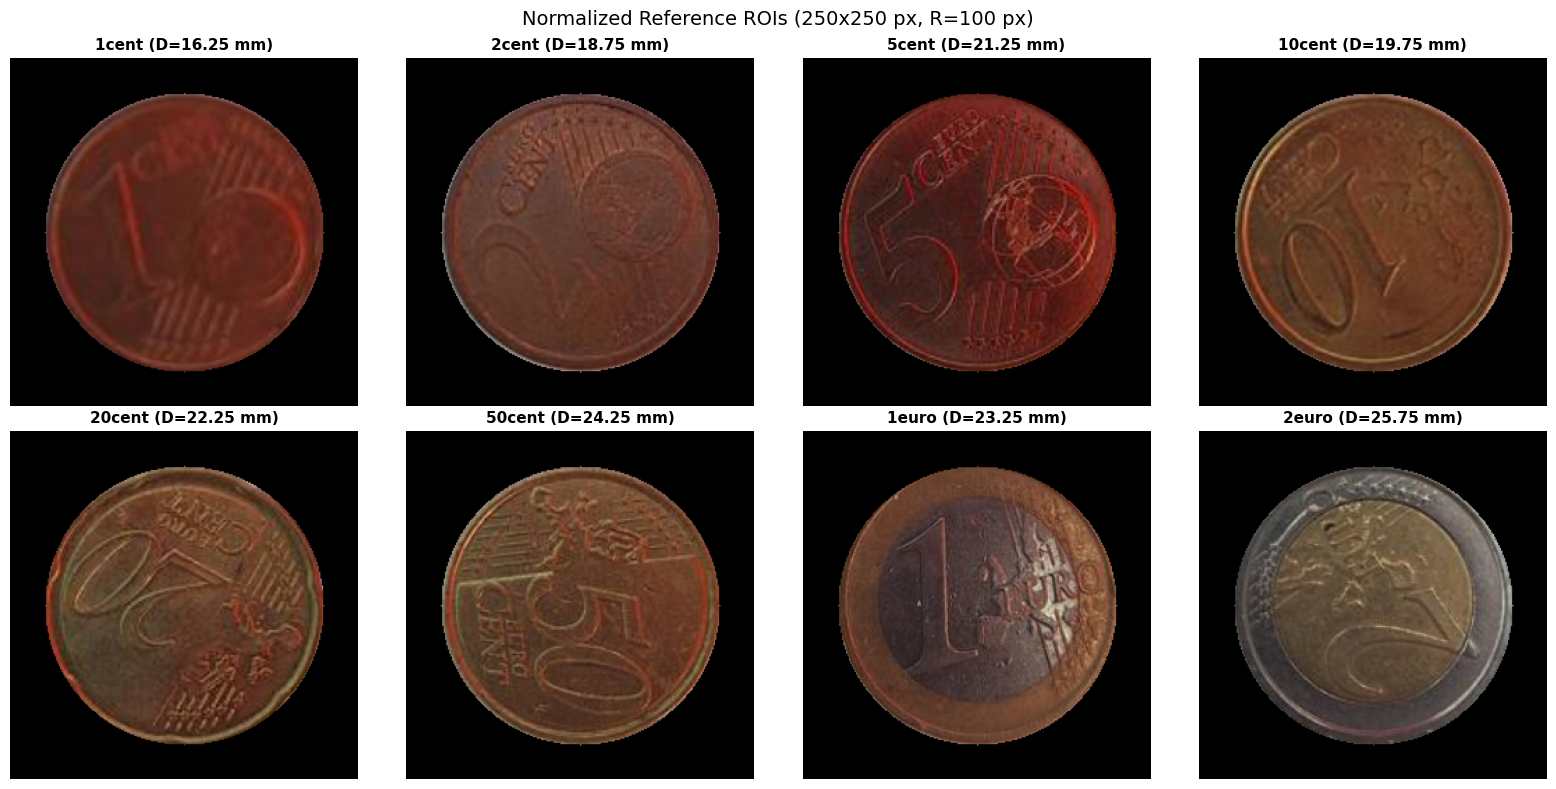

In [3]:

def detect_reference_circle(img_bgr: np.ndarray) -> Tuple[float, float, float]:
    """Detect the coin circle (cx, cy, radius) on a clean reference image."""

    # Convert to grayscale and blur slightly to suppress high-frequency noise
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    blurred = cv2.medianBlur(gray, 7)
    
    # Run Hough Circles to find the single coin in the image
    circles = cv2.HoughCircles(
        blurred, cv2.HOUGH_GRADIENT, dp=1.2, minDist=100,
        param1=50, param2=30, minRadius=40, maxRadius=150
    )
    if circles is not None and len(circles[0]) > 0:
        # Take the detected coin circle
        cx, cy, r = circles[0][0]
        return float(cx), float(cy), float(r)
        
    # Fallback to image center if no circle was detected
    h, w = gray.shape
    return float(w / 2.0), float(h / 2.0), float(min(w, h) * 0.45)


def extract_normalized_roi(
    img_bgr: np.ndarray, cx: float, cy: float, radius: float,
    canvas_size: int = 250, target_radius: float = 100.0
) -> np.ndarray:
    """Extract, scale, and center the coin onto a fixed canvas with a circular mask."""
    canvas_center = canvas_size / 2.0  # 125.0 px
    scale = target_radius / radius
    
    # Simple affine transformation matrix:
    # Scale the image so the coin radius becomes target_radius and translate so coin center moves to canvas center
    T = np.float32([
        [scale, 0, canvas_center - cx * scale],
        [0, scale, canvas_center - cy * scale]
    ])
    roi = cv2.warpAffine(
        img_bgr, T, (canvas_size, canvas_size),
        flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0)
    )
    
    # Create circular binary mask to remove table background and outer shadows
    mask = np.zeros((canvas_size, canvas_size), dtype=np.uint8)
    cv2.circle(mask, (int(canvas_center), int(canvas_center)), int(target_radius), 255, -1)
    
    # Keep only the pixels inside the coin disk
    return cv2.bitwise_and(roi, roi, mask=mask)


# Process and normalize all 8 reference images
ref_rois_bgr = {}
ref_circles = {}

for p in sorted(REF_DIR.glob("*.jpg")):
    name = p.stem
    img = cv2.imread(str(p))
    if img is not None:
        cx, cy, r = detect_reference_circle(img)
        ref_circles[name] = (cx, cy, r)
        ref_rois_bgr[name] = extract_normalized_roi(img, cx, cy, r)

print(f"Loaded and normalized {len(ref_rois_bgr)} reference coins.")

# Display the normalized reference coins in a 2x4 grid
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for idx, name in enumerate(ORDERED_DENOMINATIONS):
    ax = axes[idx]
    roi_rgb = cv2.cvtColor(ref_rois_bgr[name], cv2.COLOR_BGR2RGB)
    ax.imshow(roi_rgb)
    ax.set_title(f"{name} (D={DIAMETERS_MM[name]} mm)", fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("Normalized Reference ROIs (250x250 px, R=100 px)", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()


### Offline step 2: Reference Color Calibration

In this step, we calibrate decision thresholds from the 8 clean reference coins to group denominations into three macro-color categories: Bimetallic (1 euro, 2 euro), Copper (1c, 2c, 5c), and Gold (10c, 20c, 50c).

We do this in two simple stages:
1. **Bimetallic Separation (CIELAB $\Delta b^*$)**: The $b^*$ channel measures yellowness. Because 1 euro and 2 euro combine a golden alloy with silver, we compute the yellowness difference between the outer ring and the center core. A positive value indicates 1 euro (golden ring, silver core), a negative value indicates 2 euro (silver ring, golden core), while homogeneous single-metal coins stay close to zero.
2. **Copper vs Gold Separation (HSV Hue)**: For single-metal coins, we first apply White-Patch to balance the lighting. This is needed to ensure an illumination-invariant Hue measurement. Then, we check the average Hue: copper coins are reddish-orange (lower hue), whereas gold coins are distinctly yellow (higher hue).


We place the decision thresholds **halfway** between the reference classes and save a confidence margin (`half_gap`). During target classification in the Online Phase, these thresholds let us immediately prune impossible candidate denominations, while the distance from the threshold gives a continuous confidence score that prevents dirty or shaded coins from being misclassified.

Executing the cell below will plot these two boundaries that allow us to discriminate the "kind" of the coin, giving a visual interpretation on how we will classify their color during the Online phase. From the plots, we can observe that coin categories are clearly separated by their respective decision thresholds: $\Delta b^*$ in the CIELAB color space isolates bimetallic coins, while Hue in the HSV space separates monometallic ones.

We also include the `confident` threshold parameter (set to 0.5) in the calibrated profiles dictionary. This value dictates how strictly we trust a color prediction during the Online Phase: if a coin falls below the halfway point between the threshold and the closest reference coin, its color is considered uncertain. In such cases, we avoid pruning candidate denominations prematurely, letting the geometric scale and edge matching resolve potential ambiguities.


Bimetallic threshold (Delta b*): 7.72 (half-gap: 5.43)
Copper vs Gold threshold (Hue):   21.8° (half-gap: 4.2°)


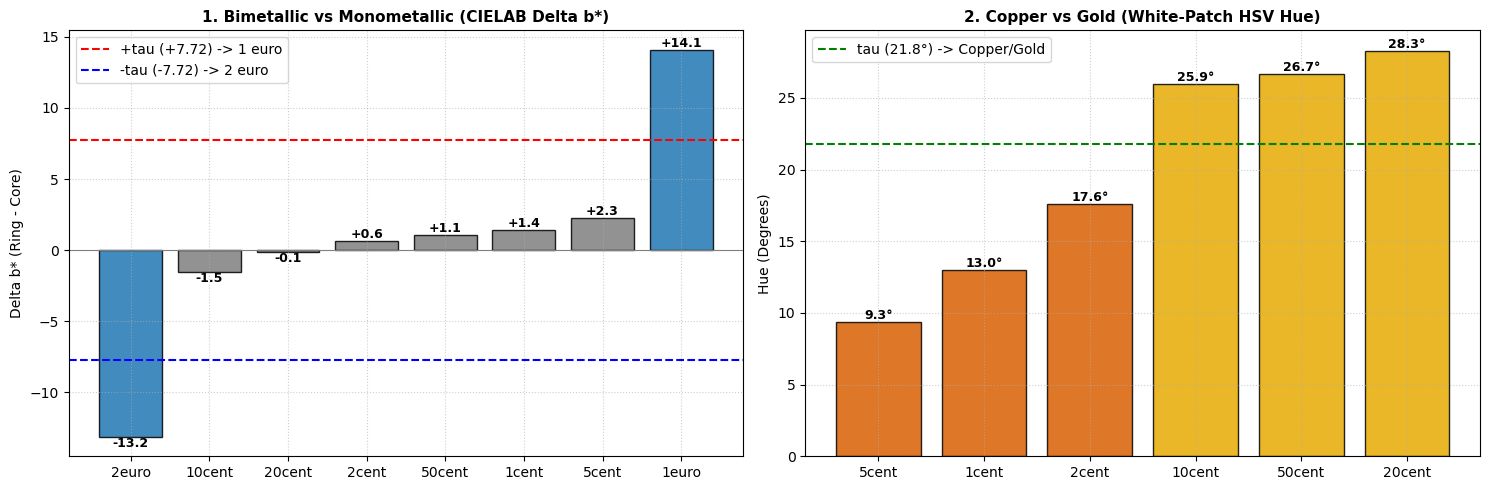

In [13]:

def ring_minus_centre(image: np.ndarray, cx: float, cy: float, r: float) -> float:
    """
    Computes the yellowness difference (Delta b*) between the outer ring and the inner core.
    """
    # Convert image from BGR to CIELAB and extract the b* channel
    lab_image = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    b_channel = lab_image[:, :, 2].astype(np.float32)

    # Compute Euclidean distance from each pixel (x, y) to coin center (cx, cy)
    h, w = image.shape[:2]
    ys, xs = np.ogrid[:h, :w]
    distances = np.hypot(xs - cx, ys - cy)

    # Define circular regions: Core is inside 60% of radius to stay clear of the metal junction, while
    # Ring is between 80% and 90% of radius to avoid the outer rim
    core_mask = distances < (0.6 * r)
    ring_mask = (distances >= 0.8 * r) & (distances < 0.9 * r)

    # Calculate average yellowness in both regions and return their difference
    mean_ring_yellowness = float(b_channel[ring_mask].mean())
    mean_core_yellowness = float(b_channel[core_mask].mean())
    return mean_ring_yellowness - mean_core_yellowness


def white_patch(image: np.ndarray) -> np.ndarray:
    """
    Applies White-Patch Retinex to remove the color cast of the scene illuminant.
    """
    # Find the 99th percentile brightness per color channel
    brightest = np.percentile(image, 99, axis=(0, 1))
    
    # Avoid division by zero if an image channel is completely dark
    brightest = np.where(brightest == 0, 1.0, brightest)
    
    # Scale channels to [0, 255] and convert back to uint8
    normalized = (image / brightest) * 255.0
    return np.clip(normalized, 0, 255).astype(np.uint8)


def coin_hue(image: np.ndarray, cx: float, cy: float, r: float) -> float:
    """
    Computes the average Hue angle in degrees (0 - 360) inside the coin.
    """
    # Create a mask for the coin interior
    mask = np.zeros(image.shape[:2], dtype=np.uint8)
    cv2.circle(mask, (round(cx), round(cy)), round(0.9 * r), 255, -1)

    # Convert normalized image to float HSV so OpenCV returns Hue in degrees [0, 360]
    hsv_image = cv2.cvtColor(image.astype(np.float32) / 255.0, cv2.COLOR_BGR2HSV)
    hue_channel = hsv_image[:, :, 0]

    # Select only the hue values inside the coin mask
    coin_hues = hue_channel[mask > 0]

    # Hue is circular around 0° (pure red). Since deep reds can wrap around above 180°
    # (e.g. 350° is equivalent to -10°), we map them to negative values to compute a proper average
    coin_hues = np.where(coin_hues > 180, coin_hues - 360, coin_hues)
    return float(coin_hues.mean())



# Here we Calibrate Bimetallic Threshold from the 8 Reference Coins

ref_deltas = {}
for name, (cx, cy, r) in ref_circles.items():
    orig_img = cv2.imread(str(REF_DIR / f"{name}.jpg"))
    ref_deltas[name] = ring_minus_centre(orig_img, cx, cy, r)

# Single-metal coins should have near-zero Delta b*, while 1 euro and 2 euro have large values
largest_single_delta = max(abs(ref_deltas[n]) for n in ref_deltas if n not in ("1euro", "2euro"))
smallest_bimetal_delta = min(abs(ref_deltas[n]) for n in ("1euro", "2euro"))

# Place threshold tau halfway between single-metal and bimetallic references
tau_bimetal = (largest_single_delta + smallest_bimetal_delta) / 2.0
bimetal_half_gap = (smallest_bimetal_delta - largest_single_delta) / 2.0



# Here we Calibrate Copper vs Gold Hue Threshold from Monometallic References

ref_hues = {}
single_metal_names = [n for n in ref_circles if n not in ("1euro", "2euro")]

for name in single_metal_names:
    cx, cy, r = ref_circles[name]
    orig_img = cv2.imread(str(REF_DIR / f"{name}.jpg"))
    # Apply White-Patch color balancing first
    wp_img = white_patch(orig_img)
    ref_hues[name] = coin_hue(wp_img, cx, cy, r)

# Copper is reddish (lower hue), Gold is yellow (higher hue)
most_yellow_copper_hue = max(ref_hues[n] for n in ("1cent", "2cent", "5cent"))
least_yellow_gold_hue = min(ref_hues[n] for n in ("10cent", "20cent", "50cent"))

# Place threshold tau halfway between the two groups
tau_hue = (most_yellow_copper_hue + least_yellow_gold_hue) / 2.0
hue_half_gap = (least_yellow_gold_hue - most_yellow_copper_hue) / 2.0


# Store calibrated parameters for use in the Online Phase
color_profiles = {
    "bimetal": {"threshold": tau_bimetal, "half_gap": bimetal_half_gap, "confident": 0.5},
    "single_metal": {"threshold": tau_hue, "half_gap": hue_half_gap, "confident": 0.5}
}

print(f"Bimetallic threshold (Delta b*): {tau_bimetal:.2f} (half-gap: {bimetal_half_gap:.2f})")
print(f"Copper vs Gold threshold (Hue):   {tau_hue:.1f}° (half-gap: {hue_half_gap:.1f}°)")



# Here we just plot Calibration Distributions for Visual Verification

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Delta b* (Bimetallic separation)
names_b = sorted(ref_deltas.keys(), key=lambda k: ref_deltas[k])
colors_b = ["#1f77b4" if n in ("1euro", "2euro") else "#7f7f7f" for n in names_b]
bars1 = ax1.bar(names_b, [ref_deltas[n] for n in names_b], color=colors_b, edgecolor="black", alpha=0.85)
ax1.bar_label(bars1, labels=[f"{ref_deltas[n]:+.1f}" for n in names_b], fontsize=9, fontweight="bold")
ax1.axhline(tau_bimetal, color="red", linestyle="--", linewidth=1.5, label=f"+tau (+{tau_bimetal:.2f}) -> 1 euro")
ax1.axhline(-tau_bimetal, color="blue", linestyle="--", linewidth=1.5, label=f"-tau (-{tau_bimetal:.2f}) -> 2 euro")
ax1.axhline(0, color="gray", linewidth=0.8)
ax1.set_title("1. Bimetallic vs Monometallic (CIELAB Delta b*)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Delta b* (Ring - Core)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper left")

# Subplot 2: White-Patch HSV Hue (Copper vs Nordic Gold separation)
names_h = sorted(ref_hues.keys(), key=lambda k: ref_hues[k])
colors_h = ["#d95f02" if n in ("1cent", "2cent", "5cent") else "#e6ab02" for n in names_h]
bars2 = ax2.bar(names_h, [ref_hues[n] for n in names_h], color=colors_h, edgecolor="black", alpha=0.85)
ax2.bar_label(bars2, labels=[f"{ref_hues[n]:.1f}°" for n in names_h], fontsize=9, fontweight="bold")
ax2.axhline(tau_hue, color="green", linestyle="--", linewidth=1.5, label=f"tau ({tau_hue:.1f}°) -> Copper/Gold")
ax2.set_title("2. Copper vs Gold (White-Patch HSV Hue)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Hue (Degrees)")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()


### Offline step 3: Edge Extraction and Polar Templates

To distinguish coins belonging to the same color class, we analyze the physical engravings on their surface. As anticipated, local keypoint detectors like SIFT perform poorly on metallic surfaces because directional reflections and shadows constantly deform the descriptors. We instead rely on the structural contours of the reliefs.

We enhance the normalized coin with CLAHE to balance local contrast and apply a bilateral filter to suppress metallic grain without blurring the engraving boundaries. After extracting edges via Canny, we intentionally remove the outer circular rim: since every coin has an identical circular perimeter, keeping it would dominate the correlation and hide the unique internal reliefs.

Because coins in target images appear with arbitrary orientations, comparing them directly in Cartesian coordinates would require rotating the 2D template at every possible angle. To solve this, we unwarp the edge image into polar coordinates $(r, \theta)$ on a $50 \times 360$ grid. In polar space, any planar rotation turns into a simple horizontal shift along the angular axis, allowing fast matching via circular cross-correlation. Finally, a gentle Gaussian blur slightly thickens the edges, making the template tolerant to sensor noise and small perspective misalignments.

Note that the parameters in `REF_EDGE_PARAMS` were tweaked manually, in order to obtain the cleanest extraction of the edges from the reference image, by visually inspecting the results. Since this was a preprocessing step on the reference set, we could afford to use different parameters for each of the 8 coins. Obviously, later in the Online phase, this step will be automated as every coin will undergo the same treatment, where the optimal edge extraction will be guaranteed by "autocanny", an algorithm that dynamically optimizes the canny parameters to obtain the best results. Furthermore, we empirically found out that grouping individual edge pixels into bins (50 in this case) yielded the best results during experimentation, probably because it adds another layer of tolerance to single-pixel misalignments.

From the output of the cell below, we can clearly see how the macro-features of the coins (for example the number 5 in the 5-cent coin) are clearly preserved in their respective polar matrices.

Generated 8 reference polar templates (50x360 float32).


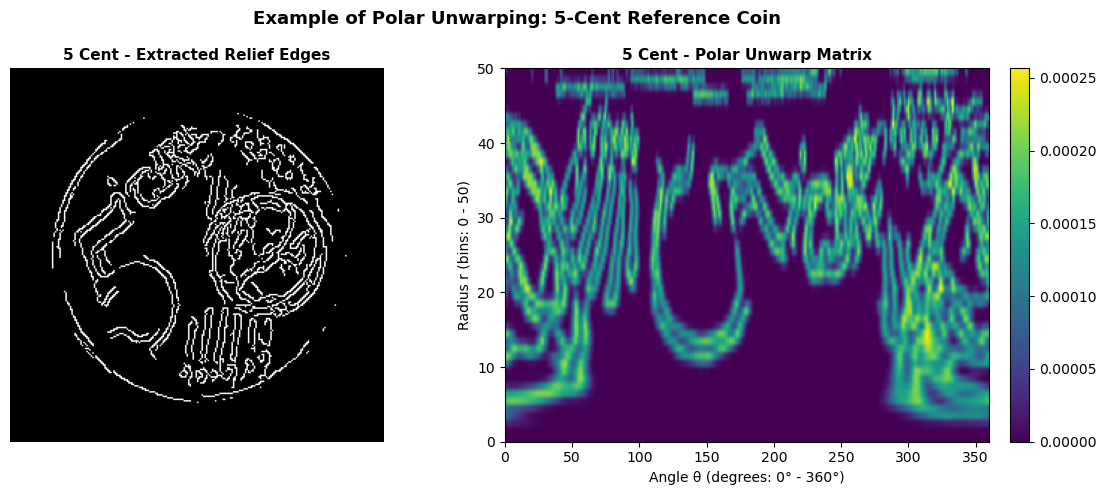

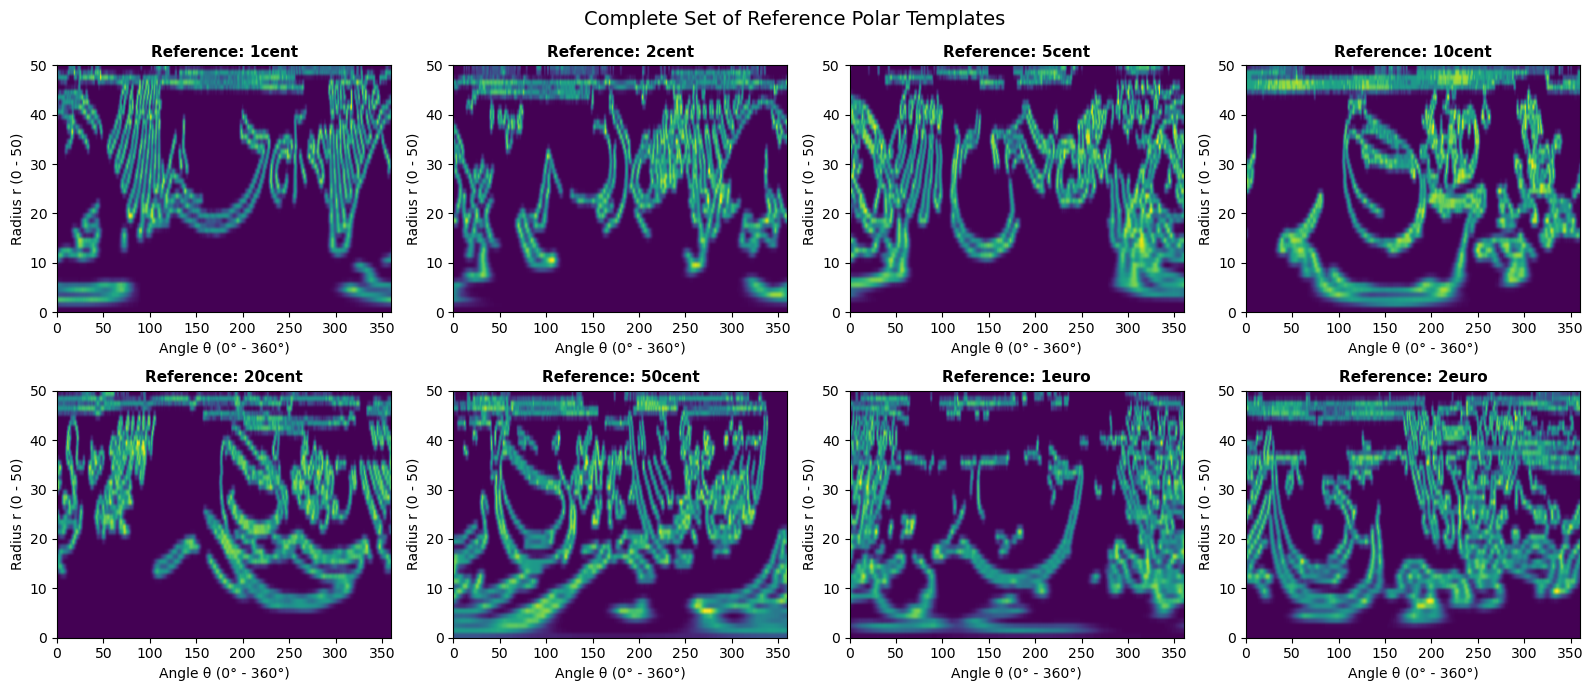

In [15]:

# Canny and Bilateral filter parameters tuned for each reference coin
REF_EDGE_PARAMS = {
    "10cent": {"d": 1, "sigma": 30, "t1": 65, "t2": 250},
    "1cent":  {"d": 5, "sigma": 80, "t1": 70, "t2": 35},
    "1euro":  {"d": 7, "sigma": 85, "t1": 50, "t2": 70},
    "20cent": {"d": 7, "sigma": 70, "t1": 60, "t2": 150},
    "2cent":  {"d": 7, "sigma": 55, "t1": 25, "t2": 65},
    "2euro":  {"d": 7, "sigma": 90, "t1": 30, "t2": 70},
    "50cent": {"d": 7, "sigma": 75, "t1": 60, "t2": 95},
    "5cent":  {"d": 7, "sigma": 80, "t1": 35, "t2": 70}
}


def extract_reference_edge(gray_roi: np.ndarray, params: Dict[str, Any]) -> np.ndarray:
    """
    Extracts coin relief edges from a normalized 250x250 grayscale ROI.
    """
    # Enhance local contrast with CLAHE
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray_roi)

    #  Bilateral Filter
    d = params.get("d", 7)
    sigma = float(params.get("sigma", 75.0))
    smoothed = cv2.bilateralFilter(enhanced, d=d, sigmaColor=sigma, sigmaSpace=sigma) if d > 0 else enhanced

    # Detect relief edges using Canny with coin-specific thresholds
    t1, t2 = int(params.get("t1", 50)), int(params.get("t2", 140))
    edges = cv2.Canny(smoothed, t1, t2)

    # Remove outer circular outer rim
    h, w = edges.shape[:2]
    ys, xs = np.ogrid[:h, :w]
    circle_mask = np.hypot(xs - 125.0, ys - 125.0) <= 99.0
    edges[~circle_mask] = 0

    return edges


def compute_polar_unwarp(
    edge_img: np.ndarray,
    center: Tuple[float, float] = (125.0, 125.0),
    max_radius: float = 100.0,
    dims: Tuple[int, int] = (50, 360),
    blur_ksize: Tuple[int, int] = (5, 5),
    normalize_energy: bool = True
) -> np.ndarray:
    """
    Unwarps a 250x250 circular edge map into a polar matrix (50 radial bins x 360 angle bins).
    """
    rad_bins, ang_bins = dims

    # Apply a mild Gaussian blur to slightly thicken edges
    blurred = cv2.GaussianBlur(edge_img, blur_ksize, 0) if (blur_ksize and blur_ksize[0] > 0) else edge_img.copy()

    #Linear polar unwarp
    polar_full = cv2.warpPolar(
        blurred, (int(max_radius), int(ang_bins)), center, max_radius,
        cv2.WARP_POLAR_LINEAR + cv2.INTER_LINEAR + cv2.WARP_FILL_OUTLIERS
    )

    #Downsample to target radial bins
    if polar_full.shape[1] != rad_bins:
        polar_matrix = cv2.resize(polar_full, (rad_bins, ang_bins), interpolation=cv2.INTER_AREA)
    else:
        polar_matrix = polar_full

    # Transpose so rows = radius r and columns = angle theta
    polar_matrix = polar_matrix.T.astype(np.float32)

    # Normalize total energy so templates with different edge counts are directly comparable
    if normalize_energy:
        total = float(np.sum(polar_matrix))
        if total > 0:
            polar_matrix /= total

    return polar_matrix



#Process and Build Polar Templates for All 8 Reference Coins
ref_edges = {}
ref_polar_templates = {}

for name in ORDERED_DENOMINATIONS:
    roi_gray = cv2.cvtColor(ref_rois_bgr[name], cv2.COLOR_BGR2GRAY)
    edges = extract_reference_edge(roi_gray, REF_EDGE_PARAMS[name])
    ref_edges[name] = edges
    ref_polar_templates[name] = compute_polar_unwarp(edges)

print(f"Generated {len(ref_polar_templates)} reference polar templates (50x360 float32).")



# Example on the 5-Cent Reference Coin

fig_ex, (ax_edge, ax_polar) = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: Extracted Cartesian Canny edges
ax_edge.imshow(ref_edges["5cent"], cmap="gray")
ax_edge.set_title("5 Cent - Extracted Relief Edges", fontsize=11, fontweight="bold")
ax_edge.axis("off")

# Subplot 2: Unwarped Polar matrix
im_ex = ax_polar.imshow(
    ref_polar_templates["5cent"],
    aspect="auto",
    cmap="viridis",
    origin="lower",
    extent=[0, 360, 0, 50]
)
ax_polar.set_title("5 Cent - Polar Unwarp Matrix", fontsize=11, fontweight="bold")
ax_polar.set_xlabel("Angle θ (degrees: 0° - 360°)")
ax_polar.set_ylabel("Radius r (bins: 0 - 50)")
fig_ex.colorbar(im_ex, ax=ax_polar, fraction=0.046, pad=0.04)

plt.suptitle("Example of Polar Unwarping: 5-Cent Reference Coin", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()



# Complete Set of Reference Polar Templates

fig_all, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for idx, name in enumerate(ORDERED_DENOMINATIONS):
    ax = axes[idx]
    mat = ref_polar_templates[name]
    ax.imshow(mat, aspect="auto", cmap="viridis", origin="lower", extent=[0, 360, 0, 50])
    ax.set_title(f"Reference: {name}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Angle θ (0° - 360°)")
    ax.set_ylabel("Radius r (0 - 50)")

plt.suptitle("Complete Set of Reference Polar Templates", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

## Target Processing and Classification (Online Phase)

This is the phase of the pipeline that directly classifies all the instances of the coins found in the images of the target set, and computes the total monetary value.
In this section we will define all detection, feature extraction, and classification steps. Here is a brief summary of the role of each component of this phase:
1. **Coin detection**:
   - `preprocess_for_detection`: extraction of CIELAB $L^*$ luminance channel + median filter + Non-Local Means (NLM) + Gaussian blur + CLAHE.
   - `detect_circles_hough`: Hough Gradient circle detection (`dp=1.3, minDist=100, param1=50, param2=30`).
   - `filter_by_edge_support`: validation of candidates by calculating the alignment between the circle circumference and image Sobel gradient vectors (requiring $\ge 0.85$ edge support score).
2. **Color Classification**:
   - Computes $\Delta b^*$ and White-Patch Hue on the coin disc, returning group (`kind`), continuous confidence score, and boolean confidence flag.
   - **Crucial preprocessing step**: Target set photographs have swapped Red and Blue channels compared to reference images. We re-align the chromatic channels prior to color feature extraction.
3. **Circular ZNCC via Fast Fourier Transform (FFT)**:
   - Evaluates normalized cross-correlation across all 360 relative angles $\Delta\theta$ in $O(N_r N_\theta \log N_\theta)$ time:
     $$\text{CorrMatrix}(\Delta\theta, r) = \mathcal{F}^{-1}\left( \mathcal{F}(T_{\text{norm}}) \cdot \mathcal{F}(R_{\text{norm}})^* \right)$$
4. **Single-Coin vs Multi-Coin Classifiers**:
   - Single-coin: color-pruned ZNCC template matching.
   - Multi-coin: Soft-CSP multi-modal optimizer minimizing scale CV and ratio errors, with soft candidate pruning and dynamic ZNCC tie-breaking.

In [6]:
# ==============================================================================
# 3.1 DETECTION FUNCTIONS: HOUGH CIRCLES + RADIAL GRADIENT SUPPORT VALIDATION
# ==============================================================================

@dataclass(frozen=True)
class Circle:
    cx: float
    cy: float
    radius: float


def preprocess_for_detection(image: np.ndarray) -> np.ndarray:
    """Denoise and enhance luminance for Hough Circle detection."""
    # Extract CIELAB luminance channel to eliminate chromatic reflections
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)[:, :, 0]
    gray = cv2.medianBlur(gray, 3)
    gray = cv2.fastNlMeansDenoising(gray, h=45.0, templateWindowSize=7, searchWindowSize=21)
    gray = cv2.GaussianBlur(gray, (11, 11), 0)
    clahe = cv2.createCLAHE(clipLimit=1.2, tileGridSize=(16, 16))
    return clahe.apply(gray)


def detect_circles_hough(
    preprocessed: np.ndarray,
    dp: float = 1.3,
    min_dist: float = 100.0,
    param1: float = 50.0,
    param2: float = 30.0,
    min_radius: int = 50,
    max_radius: int = 130
) -> List[Circle]:
    """Detect candidate circles using Hough Gradient Transform."""
    raw = cv2.HoughCircles(
        preprocessed, cv2.HOUGH_GRADIENT,
        dp=dp, minDist=min_dist, param1=param1, param2=param2,
        minRadius=min_radius, maxRadius=max_radius
    )
    if raw is None:
        return []
    return [Circle(cx=float(cx), cy=float(cy), radius=float(r)) for cx, cy, r in raw[0]]


def filter_by_edge_support(
    gray: np.ndarray,
    circles: List[Circle],
    min_score: float = 0.85,
    n_samples: int = 72
) -> List[Circle]:
    """Validate circles by checking radial alignment of Sobel image gradients along circumference."""
    if not circles:
        return []
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.sqrt(gx**2 + gy**2)
    angle = np.arctan2(gy, gx)
    h, w = mag.shape
    thetas = np.linspace(0, 2 * np.pi, n_samples, endpoint=False)
    cos_t, sin_t = np.cos(thetas), np.sin(thetas)
    
    kept = []
    for c in circles:
        px = np.clip(np.round(c.cx + c.radius * cos_t).astype(int), 0, w - 1)
        py = np.clip(np.round(c.cy + c.radius * sin_t).astype(int), 0, h - 1)
        mags = mag[py, px]
        angles = angle[py, px]
        radial = np.arctan2(py - c.cy, px - c.cx)
        diff = np.abs(angles - radial) % np.pi
        alignment = np.cos(diff) ** 2
        tot_mag = mags.sum()
        score = float((alignment * mags).sum() / tot_mag) if tot_mag > 1e-8 else 0.0
        if score >= min_score:
            kept.append(c)
    return kept


def detect_coins_in_image(img_bgr: np.ndarray) -> List[Circle]:
    """Full coin detection pipeline on a single image."""
    prep = preprocess_for_detection(img_bgr)
    candidates = detect_circles_hough(prep)
    validated = filter_by_edge_support(prep, candidates, min_score=0.85)
    return validated

In [7]:
# ==============================================================================
# 3.2 COLOR CLASSIFICATION, EDGE EXTRACTION & FFT CIRCULAR ZNCC
# ==============================================================================

def classify_coin_color(
    img_color: np.ndarray,
    img_wp: np.ndarray,
    cx: float, cy: float, r: float,
    profiles: Dict[str, Any]
) -> Dict[str, Any]:
    """Classify coin into one of 4 macro-color groups with continuous confidence."""
    b_thr = profiles["bimetal"]["threshold"]
    b_gap = profiles["bimetal"]["half_gap"]
    delta = ring_minus_centre(img_color, cx, cy, r)
    b_conf = min(abs(abs(delta) - b_thr) / b_gap, 1.0)
    
    if delta > b_thr:
        kind = "1 euro"
        conf = b_conf
    elif delta < -b_thr:
        kind = "2 euro"
        conf = b_conf
    else:
        h_thr = profiles["single_metal"]["threshold"]
        h_gap = profiles["single_metal"]["half_gap"]
        hue = coin_hue(img_wp, cx, cy, r)
        h_conf = min(abs(hue - h_thr) / h_gap, 1.0)
        kind = "gold" if hue > h_thr else "copper"
        conf = min(b_conf, h_conf)
        
    return {
        "kind": kind,
        "confidence": round(conf, 2),
        "confident": bool(conf >= 0.5)
    }


def extract_target_coin_edge_map(
    img_bgr: np.ndarray, cx: float, cy: float, radius: float,
    canvas_size: int = 250, target_radius: float = 100.0
) -> np.ndarray:
    """Extract standardized coin edge map using adaptive Canny thresholds."""
    center = canvas_size / 2.0
    scale = target_radius / max(radius, 1.0)
    T = np.float32([
        [scale, 0, center - cx * scale],
        [0, scale, center - cy * scale]
    ])
    roi_bgr = cv2.warpAffine(
        img_bgr, T, (canvas_size, canvas_size),
        flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0)
    )
    roi_gray = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img_proc = clahe.apply(roi_gray)
    img_proc = cv2.bilateralFilter(img_proc, d=7, sigmaColor=75.0, sigmaSpace=75.0)
    
    yy, xx = np.ogrid[:canvas_size, :canvas_size]
    mask_outside = ((xx - center) ** 2 + (yy - center) ** 2) > ((target_radius - 1.0) ** 2)
    mask_inside = ~mask_outside
    
    gx = cv2.Sobel(img_proc, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img_proc, cv2.CV_32F, 0, 1, ksize=3)
    mag = np.sqrt(gx**2 + gy**2)
    vals = mag[mask_inside]
    
    t1 = int(max(25, np.percentile(vals, 75.0)))
    t2 = int(max(t1 + 25, np.percentile(vals, 92.0)))
    edge_img = cv2.Canny(img_proc, t1, t2)
    edge_img[mask_outside] = 0
    cnt = int(np.count_nonzero(edge_img))
    
    if cnt > 2800:
        t1 = int(max(30, np.percentile(vals, 82.0)))
        t2 = int(max(t1 + 30, np.percentile(vals, 95.0)))
        edge_img = cv2.Canny(img_proc, t1, t2)
        edge_img[mask_outside] = 0
    elif cnt < 800:
        t1 = int(max(18, np.percentile(vals, 65.0)))
        t2 = int(max(t1 + 20, np.percentile(vals, 85.0)))
        edge_img = cv2.Canny(img_proc, t1, t2)
        edge_img[mask_outside] = 0
        
    return edge_img


def compute_circular_zncc(target: np.ndarray, reference: np.ndarray) -> Tuple[float, int]:
    """Compute circular Zero-Normalized Cross-Correlation along angle axis via FFT."""
    t_mean, r_mean = target.mean(), reference.mean()
    t_std, r_std = target.std(), reference.std()
    denom = t_std * r_std * target.size
    if denom < 1e-12:
        return 0.0, 0
    t_norm = target - t_mean
    r_norm = reference - r_mean
    
    # FFT along angle axis (columns)
    F_t = np.fft.fft(t_norm, axis=1)
    F_r = np.fft.fft(r_norm, axis=1)
    corr_per_r = np.fft.ifft(F_t * np.conj(F_r), axis=1).real
    corr_profile = np.sum(corr_per_r, axis=0) / denom
    best_shift = int(np.argmax(corr_profile))
    best_score = float(corr_profile[best_shift])
    return best_score, best_shift

In [8]:
# ==============================================================================
# 3.3 SINGLE-COIN (ZNCC) & MULTI-COIN (SOFT-CSP) CLASSIFIERS
# ==============================================================================

def classify_single_coin(
    coin_polar: np.ndarray,
    kind: str,
    ref_polar_templates: Dict[str, np.ndarray]
) -> str:
    """Classify single coin by matching against color-pruned reference polar templates."""
    candidates = KIND_TO_CANDIDATES.get(kind, ["10cent", "20cent", "50cent"])
    best_score = -1.0
    best_cand = candidates[0]
    for cand in candidates:
        if cand in ref_polar_templates:
            score, _ = compute_circular_zncc(coin_polar, ref_polar_templates[cand])
            if score > best_score:
                best_score = score
                best_cand = cand
    return best_cand


def classify_multi_coins_csp(
    coins: List[Dict[str, Any]],
    ref_polar_templates: Dict[str, np.ndarray],
    w_viol: float = 50.0,
    w_cv: float = 20.0,
    w_ratio: float = 10.0,
    w_color: float = 3.0,
    w_base_zncc: float = 1.5,
    tau_sim: float = 4.0,
    tau_mono: float = 3.0
) -> List[str]:
    """Solve multi-coin assignment via Soft-CSP multi-modal optimization."""
    n = len(coins)
    radii = [c["radius"] for c in coins]
    
    # Candidate lists with soft color pruning for low-confidence coins
    candidate_lists = []
    for c in coins:
        k = c["kind"]
        is_conf = c.get("confident", True)
        if not is_conf and k in ("gold", "copper"):
            cands = ["1cent", "2cent", "5cent", "10cent", "20cent", "50cent"]
        elif not is_conf and k in ("1 euro", "2 euro"):
            cands = ["1euro", "2euro"]
        else:
            cands = KIND_TO_CANDIDATES.get(k, ["10cent", "20cent", "50cent"]).copy()
        candidate_lists.append(cands)
        
    # Combinatorial explosion safeguard
    num_tuples_est = int(np.prod([len(c) for c in candidate_lists]))
    if num_tuples_est > 50000:
        confs_list = sorted([(i, float(coins[i].get("confidence", 0.7))) for i in range(n)], key=lambda x: x[1])
        unconstrained = {confs_list[0][0], confs_list[1][0]}
        for i in range(n):
            if i not in unconstrained:
                k = coins[i]["kind"]
                candidate_lists[i] = KIND_TO_CANDIDATES.get(k, ["10cent", "20cent", "50cent"])

    # Precompute ZNCC scores against candidate denominations
    zncc_cache = []
    for c in coins:
        polar = c["polar"]
        scores = {}
        for cls_name in DIAMETERS_MM.keys():
            if cls_name in ref_polar_templates:
                sc, _ = compute_circular_zncc(polar, ref_polar_templates[cls_name])
                scores[cls_name] = sc
            else:
                scores[cls_name] = 0.0
        zncc_cache.append(scores)
        
    # Flag dimensional uncertainty when two detected coins have near-identical radii
    dim_uncertainty = []
    for i in range(n):
        is_close = any(abs(radii[i] - radii[j]) <= tau_sim for j in range(n) if j != i)
        dim_uncertainty.append(1.0 if is_close else 0.0)
                
    best_score = -1e9
    best_assignment = [cl[0] for cl in candidate_lists]
    
    # Search over candidate tuples
    for candidate_tuple in itertools.product(*candidate_lists):
        scales = [radii[i] / (DIAMETERS_MM[candidate_tuple[i]] / 2.0) for i in range(n)]
        mean_s = np.mean(scales)
        std_s = np.std(scales)
        scale_cv = (std_s / (mean_s + 1e-5))
        
        # Pairwise diameter ratio error
        ratio_errs = []
        violations = 0
        for i in range(n):
            for j in range(i + 1, n):
                r_ratio = radii[i] / max(radii[j], 1e-5)
                nom_ratio = DIAMETERS_MM[candidate_tuple[i]] / max(DIAMETERS_MM[candidate_tuple[j]], 1e-5)
                ratio_errs.append(abs(r_ratio - nom_ratio) / nom_ratio)
                
                # Monotonicity violations
                if radii[i] > radii[j] + tau_mono and DIAMETERS_MM[candidate_tuple[i]] < DIAMETERS_MM[candidate_tuple[j]]:
                    violations += 1
                elif radii[j] > radii[i] + tau_mono and DIAMETERS_MM[candidate_tuple[j]] < DIAMETERS_MM[candidate_tuple[i]]:
                    violations += 1
                    
        mean_ratio_err = np.mean(ratio_errs) if ratio_errs else 0.0
        geom_score = - (w_cv * scale_cv) - (w_ratio * mean_ratio_err) - (w_viol * violations)
        
        # Color mismatch penalty and ZNCC bonus
        color_pen = 0.0
        zncc_bonus = 0.0
        for i in range(n):
            assigned = candidate_tuple[i]
            pred_kind = coins[i]["kind"]
            cand_kind = CLASS_TO_KIND.get(assigned, pred_kind)
            conf = min(float(coins[i].get("confidence", 0.7)), 1.0)
            
            if cand_kind != pred_kind:
                color_pen += (w_color * conf)
                
            W_i = w_base_zncc * (1.0 + 1.0 * (1.0 - conf) + 1.0 * dim_uncertainty[i])
            zncc_bonus += W_i * max(0.0, zncc_cache[i][assigned])
            
        total_score = geom_score - color_pen + zncc_bonus
        if total_score > best_score:
            best_score = total_score
            best_assignment = list(candidate_tuple)
            
    return best_assignment

## 4. Visual Inspection on a Sample of Target Images

We now test our detection and classification pipeline on a diverse sample of 4 target scenes (including both single-coin and multi-coin images). For each image we display:
- Detected coin circumferences and centers.
- Predicted denomination labels and individual monetary values.
- Image partial sum.

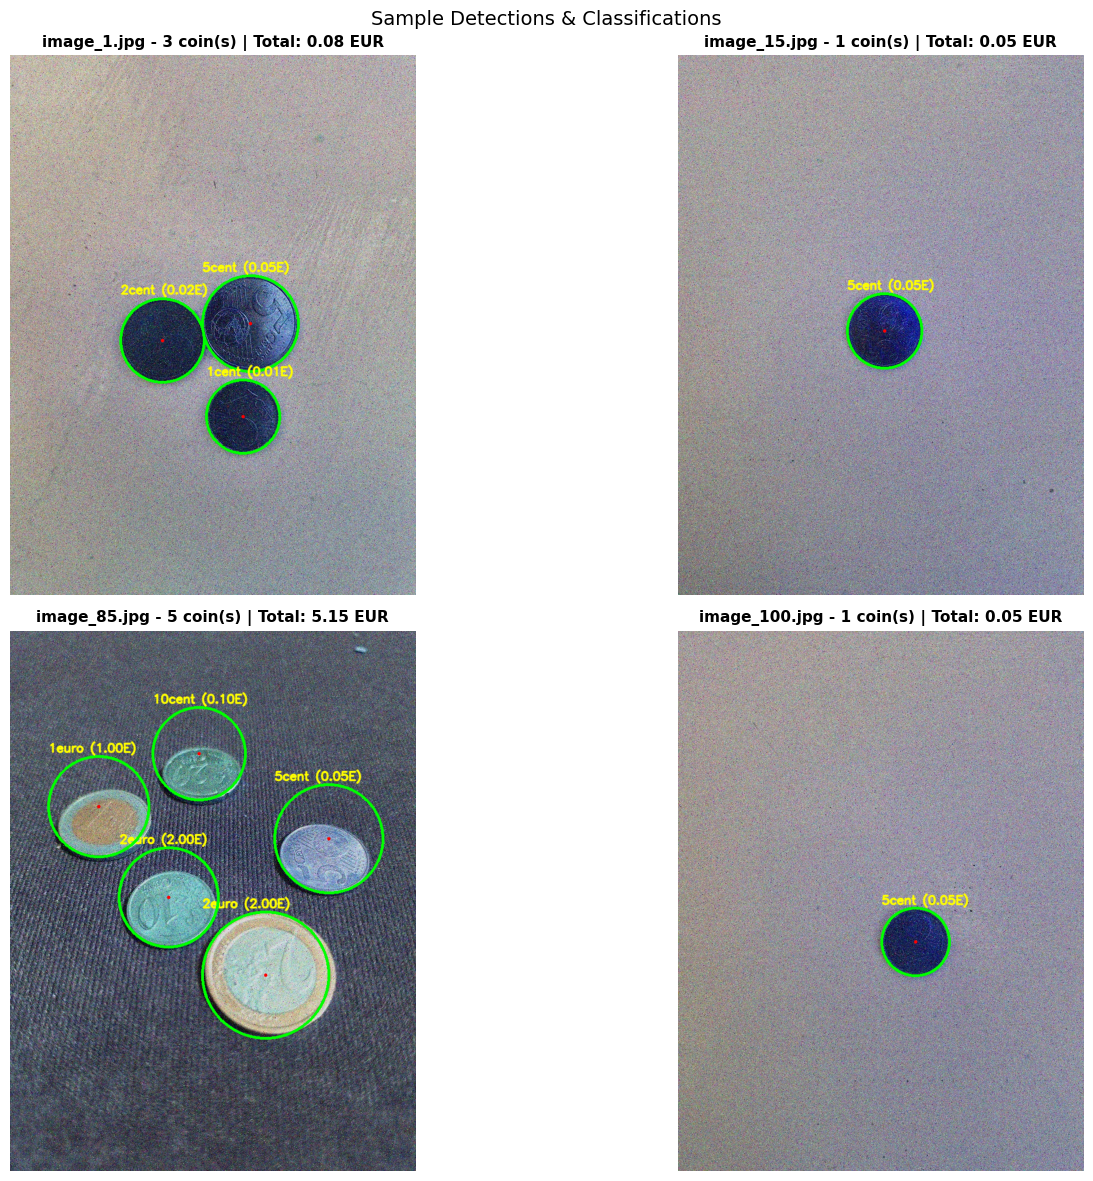

In [9]:
# ==============================================================================
# 4.1 VISUAL INSPECTION ON A SAMPLE OF 4 TARGET SCENES
# ==============================================================================

sample_names = ["image_1.jpg", "image_15.jpg", "image_85.jpg", "image_100.jpg"]
sample_paths = [TARGET_DIR / s for s in sample_names if (TARGET_DIR / s).exists()]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, p in enumerate(sample_paths):
    img_bgr = cv2.imread(str(p))
    # Correct swapped R/B channels on target images for color processing
    img_color = cv2.cvtColor(img_bgr, cv2.COLOR_RGB2BGR)
    img_wp = white_patch(img_color)
    circles = detect_coins_in_image(img_bgr)
    
    # Process detected coins
    coins_data = []
    for c in circles:
        col_info = classify_coin_color(img_color, img_wp, c.cx, c.cy, c.radius, color_profiles)
        edge_map = extract_target_coin_edge_map(img_bgr, c.cx, c.cy, c.radius)
        polar_mat = compute_polar_unwarp(edge_map)
        coins_data.append({
            "cx": c.cx, "cy": c.cy, "radius": c.radius,
            "kind": col_info["kind"], "confidence": col_info["confidence"],
            "confident": col_info["confident"], "polar": polar_mat
        })
        
    # Classify
    if len(coins_data) == 1:
        assigned = [classify_single_coin(coins_data[0]["polar"], coins_data[0]["kind"], ref_polar_templates)]
    elif len(coins_data) > 1:
        assigned = classify_multi_coins_csp(coins_data, ref_polar_templates)
    else:
        assigned = []
        
    # Render visualization
    disp_img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    partial_val = sum(COIN_VALUES[cls] for cls in assigned)
    
    for i, c in enumerate(coins_data):
        label = assigned[i]
        val = COIN_VALUES[label]
        cv2.circle(disp_img, (round(c["cx"]), round(c["cy"])), round(c["radius"]), (0, 255, 0), 3)
        cv2.circle(disp_img, (round(c["cx"]), round(c["cy"])), 3, (255, 0, 0), -1)
        text = f"{label} ({val:.2f}E)"
        cv2.putText(
            disp_img, text, (round(c["cx"] - c["radius"]), round(c["cy"] - c["radius"] - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 0), 2, cv2.LINE_AA
        )
        
    ax = axes[idx]
    ax.imshow(disp_img)
    ax.set_title(f"{p.name} - {len(assigned)} coin(s) | Total: {partial_val:.2f} EUR", fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("Sample Detections & Classifications", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

## 5. Full Dataset Processing & Official Output

In this section we execute the pipeline across all 142 images in the target set and print the output formatted **strictly according to the official assignment specification**:
```
image_X.jpg - K coin(s) found:
  Coin 1 {value: ...}
  ...
  Partial Amount {value: ...}
...
Total Amount: ... €
```

In [10]:
# ==============================================================================
# 5.1 FULL TARGET SET PROCESSING & OFFICIAL OUTPUT
# ==============================================================================

def natural_sort_key(path: Path) -> int:
    match = re.search(r"\d+", path.stem)
    return int(match.group()) if match else 0

target_image_paths = sorted(TARGET_DIR.glob("*.jpg"), key=natural_sort_key)
print(f"Processing all {len(target_image_paths)} target images...\n")

grand_total = 0.0
predictions_manifest = {}

for p in target_image_paths:
    img_name = p.stem
    img_bgr = cv2.imread(str(p))
    if img_bgr is None:
        continue
        
    # Invert swapped R/B channels on target images for color analysis
    img_color = cv2.cvtColor(img_bgr, cv2.COLOR_RGB2BGR)
    img_wp = white_patch(img_color)
    circles = detect_coins_in_image(img_bgr)
    
    coins_data = []
    for idx_c, c in enumerate(circles):
        col_info = classify_coin_color(img_color, img_wp, c.cx, c.cy, c.radius, color_profiles)
        edge_map = extract_target_coin_edge_map(img_bgr, c.cx, c.cy, c.radius)
        polar_mat = compute_polar_unwarp(edge_map)
        coins_data.append({
            "coin_id": idx_c,
            "center": [c.cx, c.cy],
            "radius": c.radius,
            "kind": col_info["kind"],
            "confidence": col_info["confidence"],
            "confident": col_info["confident"],
            "polar": polar_mat
        })
        
    if len(coins_data) == 1:
        assigned = [classify_single_coin(coins_data[0]["polar"], coins_data[0]["kind"], ref_polar_templates)]
    elif len(coins_data) > 1:
        assigned = classify_multi_coins_csp(coins_data, ref_polar_templates)
    else:
        assigned = []
        
    for i, c in enumerate(coins_data):
        c["class"] = assigned[i]
        
    predictions_manifest[img_name] = {
        "image_name": img_name,
        "coins": coins_data
    }
    
    # Official assignment output format
    print(f"{p.name} - {len(assigned)} coin(s) found:")
    partial = 0.0
    for j, label in enumerate(assigned, 1):
        v = COIN_VALUES[label]
        partial += v
        print(f"  Coin {j} {{value: {v:.3f}}}")
    print(f"  Partial Amount {{value: {partial:.3f}}}")
    grand_total += partial

print(f"\n==========================================")
print(f"Total Amount: {grand_total:.2f} €")
print(f"==========================================")

Processing all 142 target images...

image_1.jpg - 3 coin(s) found:
  Coin 1 {value: 0.050}
  Coin 2 {value: 0.010}
  Coin 3 {value: 0.020}
  Partial Amount {value: 0.080}
image_2.jpg - 1 coin(s) found:
  Coin 1 {value: 0.100}
  Partial Amount {value: 0.100}
image_3.jpg - 6 coin(s) found:
  Coin 1 {value: 0.100}
  Coin 2 {value: 0.050}
  Coin 3 {value: 0.050}
  Coin 4 {value: 0.020}
  Coin 5 {value: 0.050}
  Coin 6 {value: 0.100}
  Partial Amount {value: 0.370}
image_4.jpg - 1 coin(s) found:
  Coin 1 {value: 0.100}
  Partial Amount {value: 0.100}
image_5.jpg - 1 coin(s) found:
  Coin 1 {value: 0.100}
  Partial Amount {value: 0.100}
image_6.jpg - 1 coin(s) found:
  Coin 1 {value: 0.200}
  Partial Amount {value: 0.200}
image_7.jpg - 3 coin(s) found:
  Coin 1 {value: 0.500}
  Coin 2 {value: 0.500}
  Coin 3 {value: 0.050}
  Partial Amount {value: 1.050}
image_8.jpg - 1 coin(s) found:
  Coin 1 {value: 0.020}
  Partial Amount {value: 0.020}
image_9.jpg - 1 coin(s) found:
  Coin 1 {value: 0.0

## 6. Quantitative Evaluation against Ground Truth

When Ground Truth annotations (`annotations_with_position.csv`) are available, we benchmark the entire pipeline:
1. **Hungarian Bipartite Spatial Matching**: pair predicted coin centers with ground truth annotations minimizing Euclidean distance ($d \le 50$ px for True Positives).
2. **Detection Metrics**: Precision, Recall, F1-Score.
3. **Classification Metrics**:
   - Accuracy on Detected Coins.
   - Breakdown for Single-Coin (ZNCC) and Multi-Coin (Soft-CSP).
   - $8 \times 8$ Confusion Matrix across all denominations.
4. **Monetary Counting Metrics**: Mean Absolute Error (MAE) per image and exact count percentage.

Loaded ground truth annotations from: annotations_with_position.csv (328 annotated coins)

                 PIPELINE EVALUATION REPORT
1. DETECTION METRICS:
   - Ground Truth Coins: 328
   - Detected Coins:     328
   - True Positives:     325 / 328 (99.09%)
   - Precision / Recall: 99.09% / 99.09%
   - Detection F1-Score: 99.09%

2. CLASSIFICATION METRICS:
   - Overall Accuracy (on detected): 72.00% (234/325)
   - Single-Coin Subpipeline (ZNCC):  62.26% (33/53)
   - Multi-Coin Subpipeline (CSP):    73.90% (201/272)

3. MONETARY COUNTING METRICS:
   - Ground Truth Total:       134.13 EUR
   - Pipeline Predicted Total: 138.54 EUR
   - Difference:               +4.41 EUR (3.29% error)
   - Mean Absolute Error (MAE): 0.18 EUR / image
   - Exact Matching Images:     75 / 142 (52.82%)


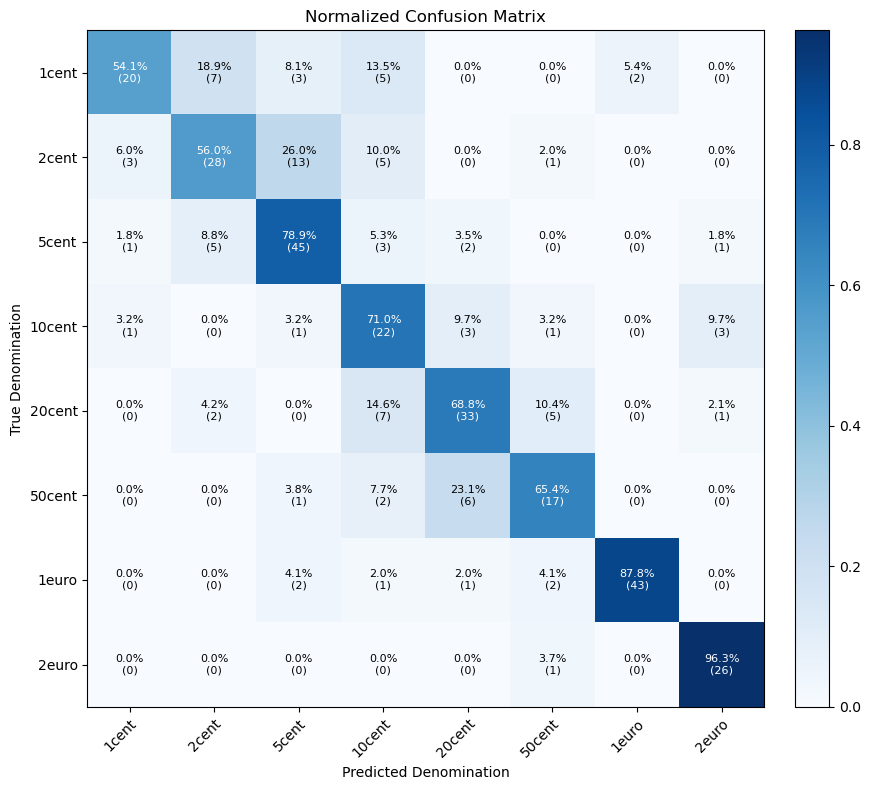

In [11]:
# ==============================================================================
# 6.1 GROUND TRUTH EVALUATION & CONFUSION MATRIX
# ==============================================================================

# Search for Ground Truth annotations CSV
gt_candidate_paths = [
    Path("annotations_with_position.csv"),
    Path("pipeline/conf/annotations_with_position.csv"),
    DATASET_DIR / "annotations_with_position.csv"
]
gt_path = next((p for p in gt_candidate_paths if p.exists()), None)

if gt_path is None:
    print("Notice: annotations_with_position.csv not found. Skipping ground truth benchmarking.")
else:
    df_gt = pd.read_csv(gt_path)
    
    # Map numerical denomination to denomination name string
    DENOM_MAP = {
        1: "1cent", 2: "2cent", 5: "5cent", 10: "10cent",
        20: "20cent", 50: "50cent", 100: "1euro", 200: "2euro"
    }
    df_gt["image_stem"] = df_gt["image"].apply(lambda x: str(x).replace(".jpg", "").replace(".png", "").strip())
    df_gt["gt_class"] = df_gt["denomination_cent"].map(DENOM_MAP)
    
    print(f"Loaded ground truth annotations from: {gt_path.name} ({len(df_gt)} annotated coins)\n")
    
    gt_by_image = {}
    for _, row in df_gt.iterrows():
        img_n = row["image_stem"]
        gt_by_image.setdefault(img_n, []).append({
            "cx": float(row["cx"]), "cy": float(row["cy"]), "class": row["gt_class"]
        })
        
    tp_count, fp_count, fn_count = 0, 0, 0
    y_true, y_pred = [], []
    single_correct, single_tot = 0, 0
    multi_correct, multi_tot = 0, 0
    gt_total_eur, pred_total_eur = 0.0, 0.0
    mae_list, exact_matches = [], 0
    
    for img_name, pred_entry in predictions_manifest.items():
        gts = gt_by_image.get(img_name, [])
        preds = pred_entry.get("coins", [])
        
        gt_img_val = sum(COIN_VALUES.get(g["class"], 0.0) for g in gts)
        pred_img_val = sum(COIN_VALUES.get(p["class"], 0.0) for p in preds)
        gt_total_eur += gt_img_val
        pred_total_eur += pred_img_val
        err = abs(gt_img_val - pred_img_val)
        mae_list.append(err)
        if err < 1e-4:
            exact_matches += 1
            
        if not gts and not preds:
            continue
        if not gts:
            fp_count += len(preds)
            continue
        if not preds:
            fn_count += len(gts)
            continue
            
        # Cost matrix for Hungarian matching based on Euclidean center distance
        cost_matrix = np.zeros((len(preds), len(gts)))
        for i, p in enumerate(preds):
            for j, g in enumerate(gts):
                cost_matrix[i, j] = np.hypot(p["center"][0] - g["cx"], p["center"][1] - g["cy"])
                
        pred_idx, gt_idx = linear_sum_assignment(cost_matrix)
        matched_preds, matched_gts = set(), set()
        
        for pi, gi in zip(pred_idx, gt_idx):
            if cost_matrix[pi, gi] <= 50.0:  # 50 px distance threshold for True Positives
                tp_count += 1
                matched_preds.add(pi)
                matched_gts.add(gi)
                true_c = gts[gi]["class"]
                pred_c = preds[pi]["class"]
                y_true.append(true_c)
                y_pred.append(pred_c)
                
                is_correct = (true_c == pred_c)
                if len(preds) == 1:
                    single_tot += 1
                    if is_correct: single_correct += 1
                else:
                    multi_tot += 1
                    if is_correct: multi_correct += 1
                    
        fp_count += len(preds) - len(matched_preds)
        fn_count += len(gts) - len(matched_gts)
        
    prec = tp_count / (tp_count + fp_count) if (tp_count + fp_count) > 0 else 0.0
    rec = tp_count / (tp_count + fn_count) if (tp_count + fn_count) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    
    acc_detected = sum(yt == yp for yt, yp in zip(y_true, y_pred)) / len(y_true) if y_true else 0.0
    acc_single = (single_correct / single_tot * 100) if single_tot > 0 else 0.0
    acc_multi = (multi_correct / multi_tot * 100) if multi_tot > 0 else 0.0
    
    print("=" * 70)
    print("                 PIPELINE EVALUATION REPORT")
    print("=" * 70)
    print(f"1. DETECTION METRICS:")
    print(f"   - Ground Truth Coins: {len(df_gt)}")
    print(f"   - Detected Coins:     {len(y_true) + fp_count}")
    print(f"   - True Positives:     {tp_count} / {len(df_gt)} ({rec*100:.2f}%)")
    print(f"   - Precision / Recall: {prec*100:.2f}% / {rec*100:.2f}%")
    print(f"   - Detection F1-Score: {f1*100:.2f}%")
    print(f"\n2. CLASSIFICATION METRICS:")
    print(f"   - Overall Accuracy (on detected): {acc_detected*100:.2f}% ({sum(yt == yp for yt, yp in zip(y_true, y_pred))}/{len(y_true)})")
    print(f"   - Single-Coin Subpipeline (ZNCC):  {acc_single:.2f}% ({single_correct}/{single_tot})")
    print(f"   - Multi-Coin Subpipeline (CSP):    {acc_multi:.2f}% ({multi_correct}/{multi_tot})")
    print(f"\n3. MONETARY COUNTING METRICS:")
    print(f"   - Ground Truth Total:       {gt_total_eur:.2f} EUR")
    print(f"   - Pipeline Predicted Total: {pred_total_eur:.2f} EUR")
    print(f"   - Difference:               {pred_total_eur - gt_total_eur:+.2f} EUR ({abs(pred_total_eur - gt_total_eur)/gt_total_eur*100:.2f}% error)")
    print(f"   - Mean Absolute Error (MAE): {np.mean(mae_list):.2f} EUR / image")
    print(f"   - Exact Matching Images:     {exact_matches} / {len(mae_list)} ({exact_matches/len(mae_list)*100:.2f}%)")
    print("=" * 70)
    
    # Plot Confusion Matrix
    cm = confusion_matrix(y_true, y_pred, labels=ORDERED_DENOMINATIONS)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(cm_norm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=ORDERED_DENOMINATIONS,
        yticklabels=ORDERED_DENOMINATIONS,
        ylabel='True Denomination',
        xlabel='Predicted Denomination',
        title='Normalized Confusion Matrix'
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    
    thresh = cm_norm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f"{cm_norm[i, j]*100:.1f}%\n({cm[i, j]})",
                    ha="center", va="center",
                    color="white" if cm_norm[i, j] > thresh else "black",
                    fontsize=8)
    plt.tight_layout()
    plt.show()